# Analyse

Ce notebook répond à la question métier à partir de la table `sessions_analysis`, construite dans `02_data-cleaning.ipynb`. Il suit les axes du cadrage : Funnel, Canaux d'acquisition, Public touché, Évolution.

**Pourquoi ces axes ?** Doctoome mène des campagnes d'acquisition  et veut que les personnes concernées aillent jusqu'au résultat. J'ai donc privilégié ce qui aide à décider : où l'on perd les gens (Funnel), quels canaux rapportent des résultats (Canaux d'acquisition), si le bon public est touché (Public touché). L'Évolution vient en dernier, en contexte : 9 semaines ne suffisent pas pour une tendance. Je n'ai pas analysé le détail des réponses : le résultat en découle directement, et ce sont des données de santé sensibles qui n'apportaient pas de levier d'action.

In [1]:
import os, duckdb
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
os.makedirs("figures", exist_ok=True)
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")


In [2]:
con.execute("CREATE VIEW sessions AS SELECT * FROM 'data_clean/sessions_analysis.parquet'")

## 1. Funnel
Combien de personnes vont au bout du questionnaire, et à quelle étape en perd-on le plus ?

### Étapes du parcours
Nombre de sessions qui atteignent chaque étape, de l'arrivée sur la page jusqu'au résultat.

In [3]:
query = """
    SELECT 'arrivée' AS etape, COUNT(*) AS n                 FROM sessions
    UNION ALL SELECT 'début',    SUM(started::INT)           FROM sessions
    UNION ALL SELECT 'Q1',       SUM((nb_answers >= 1)::INT) FROM sessions
    UNION ALL SELECT 'Q2',       SUM((nb_answers >= 2)::INT) FROM sessions
    UNION ALL SELECT 'Q3',       SUM((nb_answers >= 3)::INT) FROM sessions
    UNION ALL SELECT 'Q4',       SUM((nb_answers >= 4)::INT) FROM sessions
    UNION ALL SELECT 'Q5',       SUM((nb_answers >= 5)::INT) FROM sessions
    UNION ALL SELECT 'résultat', SUM(completed::INT)         FROM sessions
"""
funnel = con.sql(query).df()
funnel

,etape,n
0,arrivée,26000.0
1,début,16774.0
2,Q1,15558.0
3,Q2,14779.0
4,Q3,13920.0
5,Q4,12044.0
6,Q5,11462.0
7,résultat,11357.0


In [4]:
funnel["n"] = funnel["n"].astype(int)

### Abandon par étape
Pour chaque étape, la part des sessions qui passent à l'étape suivante. C'est ce qui montre où le parcours perd le plus de monde.

In [5]:
funnel["pct%_arrivee"]  = (100 * funnel["n"] / funnel["n"].iloc[0]).round(1)
funnel["pct%_de_l_etape_precedente"]  = (100 * funnel["n"] / funnel["n"].shift(1)).round(1)
funnel["pct%_perdus"]   = (100 - funnel["pct%_de_l_etape_precedente"]).round(1)
funnel

,etape,n,pct%_arrivee,pct%_de_l_etape_precedente,pct%_perdus
0,arrivée,26000,100.0,NaN,NaN
1,début,16774,64.5,64.5,35.5
2,Q1,15558,59.8,92.8,7.2
3,Q2,14779,56.8,95.0,5.0
4,Q3,13920,53.5,94.2,5.8
5,Q4,12044,46.3,86.5,13.5
6,Q5,11462,44.1,95.2,4.8
7,résultat,11357,43.7,99.1,0.9


### Graphique du parcours

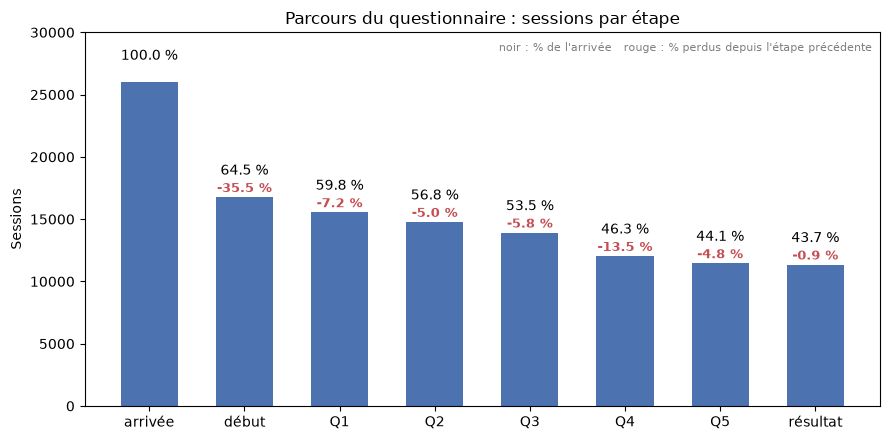

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(funnel["etape"], funnel["n"], color="#4C72B0", width=0.6)
for i, row in funnel.iterrows():
    ax.text(i, row["n"] + 1800, f"{row['pct%_arrivee']:.1f} %", ha="center")
    if i > 0:
        ax.text(i, row["n"] + 400, f"-{row['pct%_perdus']:.1f} %",
                ha="center", color="#C44E52", fontsize=9, fontweight="bold")
ax.set_ylim(0, 30000)
ax.set_title("Parcours du questionnaire : sessions par étape")
ax.set_ylabel("Sessions")
ax.text(0.99, 0.95, "noir : % de l'arrivée   rouge : % perdus depuis l'étape précédente",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig("figures/01_funnel.png", dpi=150)
plt.show()

43.7 % des visiteurs vont jusqu'au résultat. Les deux plus grosses pertes : 35.5 % repartent sans commencer, et 13,5 % abandonnent entre Q3 et Q4 (deux fois plus qu'aux autres questions). La Q4 est la seule question sur le mode de vie (activité physique) et la seule à 4 choix :  on peut tester une version simplifiée de la Q4.

### Par appareil
Le parcours se passe-t-il aussi bien sur mobile que sur ordinateur ?

In [7]:
query = """
    SELECT device_type,
           COUNT(*)                    AS sessions,
           SUM(started::INT)           AS debut,
           SUM((nb_answers >= 3)::INT) AS atteint_q3,
           SUM((nb_answers >= 4)::INT) AS atteint_q4,
           SUM(completed::INT)         AS resultat
    FROM sessions
    GROUP BY device_type
    ORDER BY sessions DESC
"""
funnel_appareil = con.sql(query).df()
funnel_appareil

,device_type,sessions,debut,atteint_q3,atteint_q4,resultat
0,mobile,16772,10518.0,8555.0,7108.0,6660.0
1,desktop,7863,5383.0,4648.0,4278.0,4072.0
2,tablet,1365,873.0,717.0,658.0,625.0


In [8]:
funnel_appareil = funnel_appareil.astype({c: int for c in funnel_appareil.columns if c != "device_type"})
funnel_appareil["pct_trafic"]            = (100 * funnel_appareil["sessions"] / funnel_appareil["sessions"].sum()).round(1)
funnel_appareil["pct_debut"]             = (100 * funnel_appareil["debut"] / funnel_appareil["sessions"]).round(1)
funnel_appareil["pct_resultat_si_debut"] = (100 * funnel_appareil["resultat"] / funnel_appareil["debut"]).round(1)
funnel_appareil["pct_perdus_q3_q4"]      = (100 - 100 * funnel_appareil["atteint_q4"] / funnel_appareil["atteint_q3"]).round(1)

In [9]:
funnel_appareil[["device_type", "sessions", "pct_trafic", "debut", "pct_debut",
          "atteint_q3", "atteint_q4", "pct_perdus_q3_q4",
          "resultat", "pct_resultat_si_debut"]]

,device_type,sessions,pct_trafic,debut,pct_debut,atteint_q3,atteint_q4,pct_perdus_q3_q4,resultat,pct_resultat_si_debut
0,mobile,16772,64.5,10518,62.7,8555,7108,16.9,6660,63.3
1,desktop,7863,30.2,5383,68.5,4648,4278,8.0,4072,75.6
2,tablet,1365,5.2,873,64.0,717,658,8.2,625,71.6


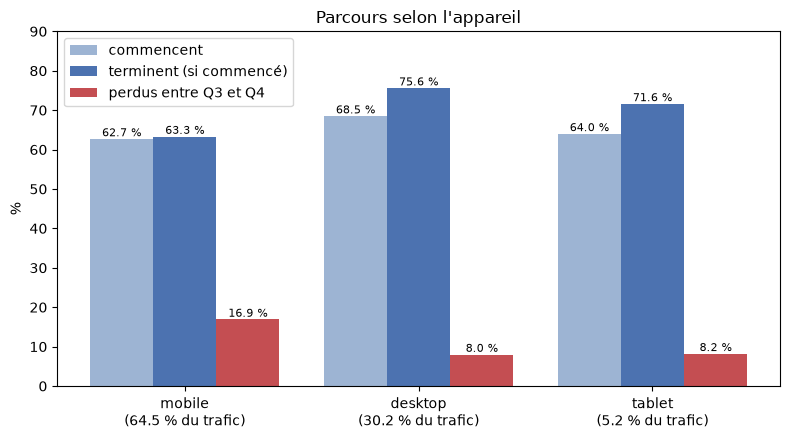

In [10]:
import numpy as np

indicateurs = {
    "pct_debut":             ("commencent",              "#9DB4D3"),
    "pct_resultat_si_debut": ("terminent (si commencé)", "#4C72B0"),
    "pct_perdus_q3_q4":      ("perdus entre Q3 et Q4",   "#C44E52"),
}

x = np.arange(len(funnel_appareil))
largeur = 0.27


fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (col, (nom, couleur)) in enumerate(indicateurs.items()):
    barres = ax.bar(x + (k - 1) * largeur, funnel_appareil[col], largeur, label=nom, color=couleur)
    ax.bar_label(barres, fmt="%.1f %%", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n({t:.1f} % du trafic)"
                    for d, t in zip(funnel_appareil["device_type"], funnel_appareil["pct_trafic"])])
ax.set_ylim(0, 90)
ax.set_ylabel("%")
ax.set_title("Parcours selon l'appareil")
ax.legend()
plt.tight_layout()
plt.savefig("figures/02_parcours_appareil.png", dpi=150)
plt.show()

Le mobile (64.5 % du trafic) perd deux fois plus de monde entre Q3 et Q4 que l'ordinateur (16.9 % contre 8 %), et termine moins souvent une fois le questionnaire commencé (63.3 % contre 75.6 %). Le décrochage à la Q4 vient donc surtout du mobile : peut-être la taille de  l'écran est la première chose à vérifier.

## 2. Canaux d'acquisition
Quels canaux apportent des questionnaires terminés, et pas seulement du trafic ?

### Par source

In [11]:
query = """
    SELECT acquisition_source,
           COUNT(*)                                           AS sessions,
           SUM(completed::INT)                                AS resultat,
           SUM((outcome_category = 'possible_risk')::INT)     AS possible_risk
    FROM sessions
    GROUP BY acquisition_source
    ORDER BY sessions DESC
"""
canaux = con.sql(query).df()

In [12]:
canaux = canaux.astype({c: int for c in canaux.columns if c != "acquisition_source"})
canaux["pct_trafic"]        = (100 * canaux["sessions"] / canaux["sessions"].sum()).round(1)
canaux["pct_resultat"]      = (100 * canaux["resultat"] / canaux["sessions"]).round(1)
canaux["pct_possible_risk"] = (100 * canaux["possible_risk"] / canaux["resultat"]).round(1)
canaux

,acquisition_source,sessions,resultat,possible_risk,pct_trafic,pct_resultat,pct_possible_risk
0,google_organic,7490,3228,591,28.8,43.1,18.3
1,google_ads,6375,2489,723,24.5,39.0,29.0
2,social,3618,1045,156,13.9,28.9,14.9
3,ai_assistant,2729,1444,205,10.5,52.9,14.2
4,referral,1790,1081,224,6.9,60.4,20.7
5,email,1707,1105,194,6.6,64.7,17.6
6,direct,1617,711,134,6.2,44.0,18.8
7,other,674,254,49,2.6,37.7,19.3


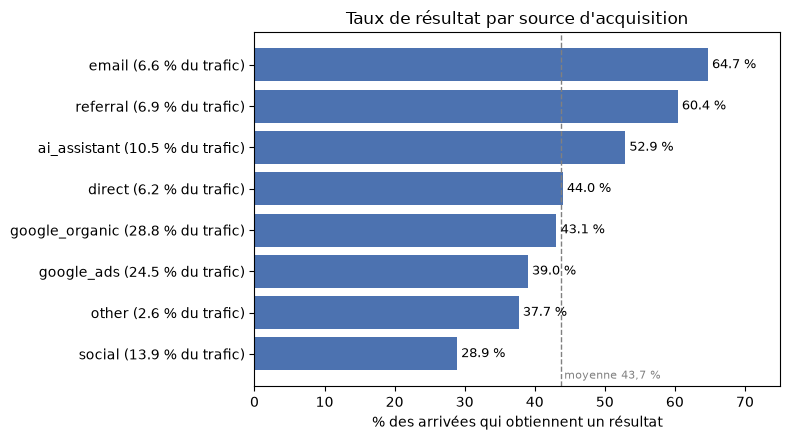

In [13]:
c = canaux.sort_values("pct_resultat")

fig, ax = plt.subplots(figsize=(8, 4.5))
barres = ax.barh([f"{s} ({t:.1f} % du trafic)" for s, t in zip(c["acquisition_source"], c["pct_trafic"])],
                 c["pct_resultat"], color="#4C72B0")
ax.bar_label(barres, fmt="%.1f %%", padding=3, fontsize=9)
ax.axvline(43.7, color="gray", linestyle="--", linewidth=1)
ax.text(44.2, -0.6, "moyenne 43,7 %", color="gray", fontsize=8)
ax.set_xlim(0, 75)
ax.set_xlabel("% des arrivées qui obtiennent un résultat")
ax.set_title("Taux de résultat par source d'acquisition")
plt.tight_layout()
plt.savefig("figures/03_resultat_par_source.png", dpi=150)
plt.show()

Google (organic + ads) apporte la moitié du trafic, mais l'email et le referral transforment le mieux respectivement 64.7% et 60.4 % de résultats contre 39% et 43.1 % de google ads et organic. Les assistants IA font mieux que Google (52.9 %) malgré un trafic modeste. Les réseaux sociaux sont le canal le plus faible (28.9 %). Google Ads ramène la plus forte part de `possible_risk` (29 %).

### Par campagne
Quelles campagnes produisent des résultats, et lesquelles touchent le public concerné ?

In [14]:
query = """
    SELECT campaign_name,
           COUNT(*)                                       AS sessions,
           SUM(completed::INT)                            AS resultat,
           SUM((outcome_category = 'possible_risk')::INT) AS possible_risk
    FROM sessions
    GROUP BY campaign_name
    ORDER BY sessions DESC
"""
campagnes = con.sql(query).df()
campagnes = campagnes.astype({c: int for c in campagnes.columns if c != "campaign_name"})
campagnes["pct_trafic"]        = (100 * campagnes["sessions"] / campagnes["sessions"].sum()).round(1)
campagnes["pct_resultat"]      = (100 * campagnes["resultat"] / campagnes["sessions"]).round(1)
campagnes["pct_possible_risk"] = (100 * campagnes["possible_risk"] / campagnes["resultat"]).round(1)
campagnes

,campaign_name,sessions,resultat,possible_risk,pct_trafic,pct_resultat,pct_possible_risk
0,no_campaign,14081,6602,1179,54.2,46.9,17.9
1,diabetes_awareness_general,3422,1554,269,13.2,45.4,17.3
2,diabetes_social_awareness,3345,954,141,12.9,28.5,14.8
3,diabetes_45plus,3337,1252,494,12.8,37.5,39.5
4,diabetes_retargeting,1815,995,193,7.0,54.8,19.4


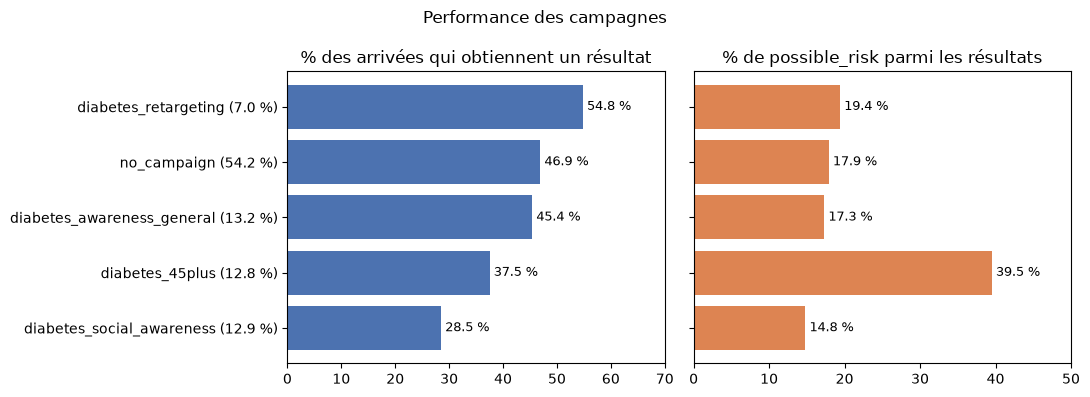

In [15]:
c = campagnes.sort_values("pct_resultat")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

b1 = ax1.barh([f"{s} ({t:.1f} %)" for s, t in zip(c["campaign_name"], c["pct_trafic"])], c["pct_resultat"], color="#4C72B0")
ax1.bar_label(b1, fmt="%.1f %%", padding=3, fontsize=9)
ax1.set_xlim(0, 70)
ax1.set_title("% des arrivées qui obtiennent un résultat")

b2 = ax2.barh([f"{s} ({t:.1f} %)" for s, t in zip(c["campaign_name"], c["pct_trafic"])], c["pct_possible_risk"], color="#DD8452")
ax2.bar_label(b2, fmt="%.1f %%", padding=3, fontsize=9)
ax2.set_xlim(0, 50)
ax2.set_title("% de possible_risk parmi les résultats")

plt.suptitle("Performance des campagnes")
plt.tight_layout()
plt.savefig("figures/04_campagnes.png", dpi=150)
plt.show()

`diabetes_45plus` touche le mieux le public concerné : 39.5 % de `possible_risk`, deux fois plus que les autres campagnes, soit 21.7 % de tous les `possible_risk` avec 12.8 % du trafic. Elle explique la forte part de `possible_risk` de Google Ads. `diabetes_social_awareness` est la plus faible sur les deux plans (28.5 % de résultats, 14.8 % de `possible_risk`). Le retargeting transforme le mieux (54.8 %).

## 3. Public touché
Qui termine le questionnaire, et où se trouvent les personnes `possible_risk` ?

### Par tranche d'âge

In [16]:
query = """
    SELECT age_band,
           COUNT(*)                                       AS sessions,
           SUM(completed::INT)                            AS resultat,
           SUM((outcome_category = 'possible_risk')::INT) AS possible_risk
    FROM sessions
    GROUP BY age_band
    ORDER BY age_band
"""
ages = con.sql(query).df()
ages = ages.astype({c: int for c in ages.columns if c != "age_band"})
ages["pct_resultat"]      = (100 * ages["resultat"] / ages["sessions"]).round(1)
ages["pct_possible_risk"] = (100 * ages["possible_risk"] / ages["resultat"]).round(1)
ages

,age_band,sessions,resultat,possible_risk,pct_resultat,pct_possible_risk
0,18-24,2763,1166,98,42.2,8.4
1,25-34,4243,1825,226,43.0,12.4
2,35-44,5955,2631,437,44.2,16.6
3,45-54,5719,2527,568,44.2,22.5
4,55-64,3722,1673,500,44.9,29.9
5,65+,2523,1095,369,43.4,33.7
6,under_18,60,28,8,46.7,28.6
7,unknown,1015,412,70,40.6,17.0


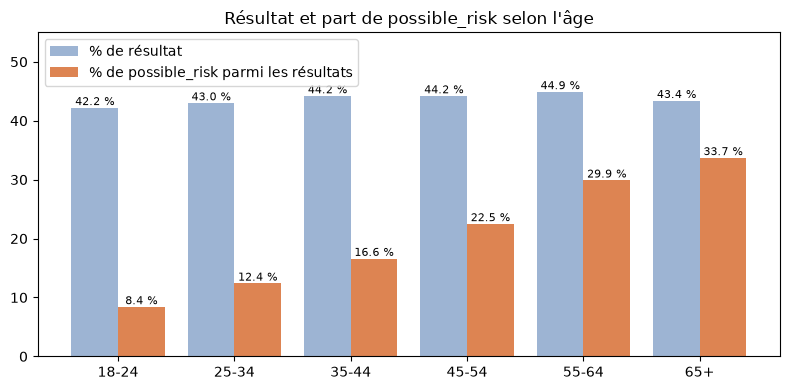

In [17]:
a = ages[~ages["age_band"].isin(["under_18", "unknown"])]

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(a))
b1 = ax.bar(x - 0.2, a["pct_resultat"], 0.4, label="% de résultat", color="#9DB4D3")
b2 = ax.bar(x + 0.2, a["pct_possible_risk"], 0.4, label="% de possible_risk parmi les résultats", color="#DD8452")
ax.bar_label(b1, fmt="%.1f %%", fontsize=8)
ax.bar_label(b2, fmt="%.1f %%", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(a["age_band"])
ax.set_ylim(0, 55)
ax.set_title("Résultat et part de possible_risk selon l'âge")
ax.legend()
plt.tight_layout()
plt.savefig("figures/05_age.png", dpi=150)
plt.show()

Toutes les tranches d'âge terminent au même rythme (42.2 à 44.9 %), mais la part de `possible_risk` monte avec l'âge : 8.4 % chez les 18-24 ans, 33.7 % chez les 65 ans et plus. Les 45 ans et plus sont donc le public à viser en priorité. La tranche `under_18` (60 sessions) est trop petite pour être interprétée.

### Âge du public par campagne
La campagne `diabetes_45plus` touche-t-elle bien les 45 ans et plus ?

In [18]:
query = """
    SELECT campaign_name,
           COUNT(*)                                                   AS sessions,
           SUM((age_band IN ('45-54', '55-64', '65+'))::INT)          AS sessions_45plus
    FROM sessions
    GROUP BY campaign_name
    ORDER BY sessions DESC
"""
cible = con.sql(query).df()
cible = cible.astype({c: int for c in cible.columns if c != "campaign_name"})
cible["pct_45plus"] = (100 * cible["sessions_45plus"] / cible["sessions"]).round(1)
cible

,campaign_name,sessions,sessions_45plus,pct_45plus
0,no_campaign,14081,6138,43.6
1,diabetes_awareness_general,3422,1490,43.5
2,diabetes_social_awareness,3345,595,17.8
3,diabetes_45plus,3337,2932,87.9
4,diabetes_retargeting,1815,809,44.6


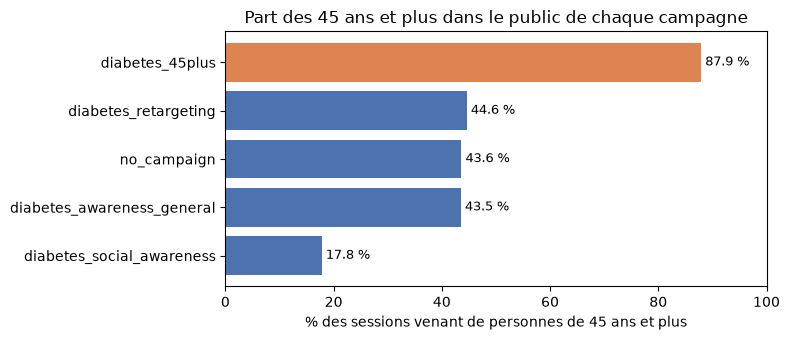

In [19]:
c = cible.sort_values("pct_45plus")
couleurs = ["#DD8452" if n == "diabetes_45plus" else "#4C72B0" for n in c["campaign_name"]]

fig, ax = plt.subplots(figsize=(8, 3.5))
barres = ax.barh(c["campaign_name"], c["pct_45plus"], color=couleurs)
ax.bar_label(barres, fmt="%.1f %%", padding=3, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% des sessions venant de personnes de 45 ans et plus")
ax.set_title("Part des 45 ans et plus dans le public de chaque campagne")
plt.tight_layout()
plt.savefig("figures/06_cible_45plus.png", dpi=150)
plt.show()

`diabetes_45plus` atteint bien sa cible : 87.9 % de son public a 45 ans ou plus, contre environ 44 % pour les autres campagnes. C'est ce qui explique sa forte part de `possible_risk` (39.5 %). À l'inverse, `diabetes_social_awareness` touche surtout des moins de 45 ans (17.8 % de 45+), ce qui explique en partie sa faible part de `possible_risk`.

### Par région et par genre
Le résultat varie-t-il selon la région ou le genre ?

In [20]:
query = """
    SELECT region,
           COUNT(*)                                       AS sessions,
           SUM(completed::INT)                            AS resultat,
           SUM((outcome_category = 'possible_risk')::INT) AS possible_risk
    FROM sessions
    GROUP BY region
    ORDER BY sessions DESC
"""
regions = con.sql(query).df()
regions = regions.astype({c: int for c in regions.columns if c != "region"})
regions["pct_resultat"]      = (100 * regions["resultat"] / regions["sessions"]).round(1)
regions["pct_possible_risk"] = (100 * regions["possible_risk"] / regions["resultat"]).round(1)
regions

,region,sessions,resultat,possible_risk,pct_resultat,pct_possible_risk
0,Hauts-de-France,2904,1257,250,43.3,19.9
1,Auvergne-Rhône-Alpes,2835,1256,245,44.3,19.5
2,Île-de-France,2789,1226,239,44.0,19.5
3,Provence-Alpes-Côte d'Azur,2780,1198,244,43.1,20.4
4,Occitanie,2779,1217,253,43.8,20.8
5,Bretagne,2763,1229,260,44.5,21.2
6,Nouvelle-Aquitaine,2729,1243,257,45.5,20.7
7,Grand Est,2691,1156,217,43.0,18.8
8,Pays de la Loire,2686,1169,239,43.5,20.4
9,unknown,1044,406,72,38.9,17.7


In [21]:
query = """
    SELECT gender,
           COUNT(*)                                       AS sessions,
           SUM(completed::INT)                            AS resultat,
           SUM((outcome_category = 'possible_risk')::INT) AS possible_risk
    FROM sessions
    GROUP BY gender
    ORDER BY sessions DESC
"""
genres = con.sql(query).df()
genres = genres.astype({c: int for c in genres.columns if c != "gender"})
genres["pct_resultat"]      = (100 * genres["resultat"] / genres["sessions"]).round(1)
genres["pct_possible_risk"] = (100 * genres["possible_risk"] / genres["resultat"]).round(1)
genres

,gender,sessions,resultat,possible_risk,pct_resultat,pct_possible_risk
0,female,12771,5569,1146,43.6,20.6
1,male,11312,4969,967,43.9,19.5
2,unknown,859,354,71,41.2,20.1
3,prefer_not_to_say,712,324,69,45.5,21.3
4,other,346,141,23,40.8,16.3


Ni la région ni le genre ne font de différence : toutes les régions obtiennent 43.0 à 45.5 % de résultats et 18.8 à 21.2 % de `possible_risk`, et les écarts entre femmes et hommes sont inférieurs à 1.1 point. Donc on peut dire que le levier de ciblage n'est ni la géographie ni le genre.

## 4. Évolution
Le questionnaire progresse-t-il au fil des semaines ?

In [22]:
query = """
    SELECT week,
           COUNT(*)                                        AS sessions,
           SUM(completed::INT)                             AS resultat,
           SUM((campaign_name = 'diabetes_45plus')::INT)   AS sessions_45plus
    FROM sessions
    GROUP BY week
    ORDER BY week
"""
semaines = con.sql(query).df()
semaines = semaines.astype({c: int for c in semaines.columns if c != "week"})
semaines["pct_resultat"] = (100 * semaines["resultat"] / semaines["sessions"]).round(1)
semaines["week_label"] = [f"S{i + 1} ({d:%d/%m})" for i, d in enumerate(semaines["week"])]

In [23]:
semaines[["week", "week_label", "sessions", "resultat", "pct_resultat", "sessions_45plus"]]

,week,week_label,sessions,resultat,pct_resultat,sessions_45plus
0,2026-06-01 00:00:00+00:00,S1 (01/06),2194,878,40.0,0
1,2026-06-08 00:00:00+00:00,S2 (08/06),2369,982,41.5,0
2,2026-06-15 00:00:00+00:00,S3 (15/06),2470,1027,41.6,0
3,2026-06-22 00:00:00+00:00,S4 (22/06),2737,1183,43.2,0
4,2026-06-29 00:00:00+00:00,S5 (29/06),2920,1264,43.3,372
5,2026-07-06 00:00:00+00:00,S6 (06/07),2902,1265,43.6,710
6,2026-07-13 00:00:00+00:00,S7 (13/07),3331,1507,45.2,754
7,2026-07-20 00:00:00+00:00,S8 (20/07),3684,1736,47.1,776
8,2026-07-27 00:00:00+00:00,S9 (27/07),3393,1515,44.7,725


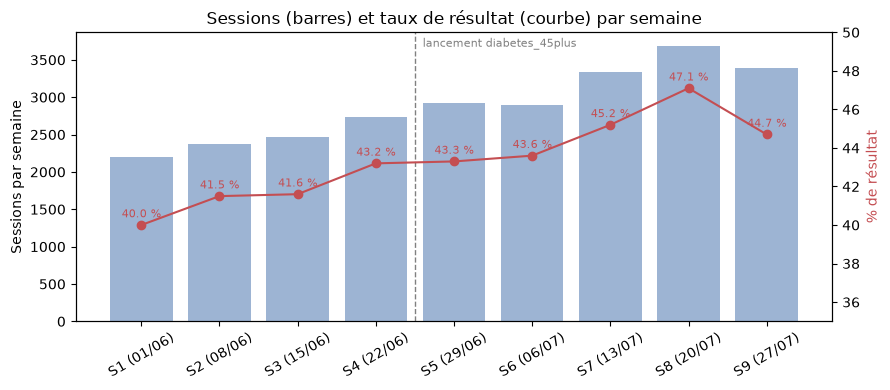

In [24]:
fig, ax1 = plt.subplots(figsize=(9, 4))
etiquettes = semaines["week_label"]

ax1.bar(etiquettes, semaines["sessions"], color="#9DB4D3")
ax1.set_ylabel("Sessions par semaine")

ax2 = ax1.twinx()
ax2.plot(etiquettes, semaines["pct_resultat"], color="#C44E52", marker="o")
for i, v in enumerate(semaines["pct_resultat"]):
    ax2.text(i, v + 0.4, f"{v:.1f} %", ha="center", fontsize=8, color="#C44E52")
ax2.set_ylim(35, 50)
ax2.set_ylabel("% de résultat", color="#C44E52")

debut = semaines.index[semaines["sessions_45plus"] > 0][0]
ax1.axvline(debut - 0.5, color="gray", linestyle="--", linewidth=1)
ax1.text(debut - 0.4, ax1.get_ylim()[1] * 0.95, "lancement diabetes_45plus", fontsize=8, color="gray")

ax1.set_title("Sessions (barres) et taux de résultat (courbe) par semaine")
ax1.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figures/07_evolution.png", dpi=150)
plt.show()

Sur 9 semaines, le trafic augmente de 68 % (2 194 à 3 684 sessions) et le taux de résultat passe de 40.0 % à 47.1 %, avant un léger recul en S9 (44.7 %). Cette hausse ne vient pas de `diabetes_45plus` : elle commence avant son lancement (S5), et cette campagne a un taux de résultat plus bas que la moyenne (37.5 % contre 43.7 %), ce qui aurait plutôt fait baisser le taux global. Deux mois ne suffisent peut-être pas à distinguer une vraie tendance d'un effet de saison.

## Synthèse

- **43.7 % des visiteurs obtiennent un résultat.** Les deux plus grosses pertes : 35.5 % repartent sans commencer, et 13.5 % abandonnent entre Q3 et Q4.
- **La perte à la Q4 vient surtout du mobile** (64.5 % du trafic) : 16.9 % de perte, contre 8.0 % sur ordinateur.
- **Volume ≠ qualité** : Google apporte la moitié du trafic mais transforme moins (39.0 à 43.1 %) que l'email (64.7 %), les liens depuis d'autres sites (referral, 60.4 %) et les assistants IA (52.9 %). Les réseaux sociaux sont le canal le plus faible (28.9 %).
- **`diabetes_45plus` touche le bon public** : 87.9 % de 45 ans et plus, 39.5 % de `possible_risk`, soit 21.7 % de tous les `possible_risk` avec 12.8 % du trafic.
- **L'âge est le seul levier de ciblage** : la part de `possible_risk` passe de 8.4 % (18-24 ans) à 33.7 % (65 ans et plus). La région et le genre ne font pas de différence.
- **Le trafic (+68 %) et le taux de résultat (40.0 % → 47.1 %) progressent** sur les 9 semaines, sans que `diabetes_45plus` l'explique.

## Recommandations

1. **Vérifier l'affichage de la Q4 sur mobile**, puis tester une version simplifiée (moins de choix, libellés plus courts) auprès d'une partie des visiteurs.
2. **Renforcer les canaux qui transforment le mieux** (email, liens depuis d'autres sites, assistants IA) et revoir `diabetes_social_awareness`, la campagne la plus faible.
3. **Étendre la logique de `diabetes_45plus`** : c'est le ciblage par l'âge qui ramène le public concerné.
4. **Mieux mesurer** : enregistrer le coût de chaque canal, indiquer la source sur tous les liens, et relier la fin du questionnaire à un bouton « Valider mes réponses » pour expliquer les 105 sessions sans résultat.